# Curated Distinctive t-SNE Visualization
This notebook generates a clean, non-overlapping t-SNE plot by mathematically selecting the points that are closest to their class centroid and furthest from other classes. This yields exactly the distinctive, non-overlapping 2D subsamples requested.

In [ ]:
import sys, os
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from matplotlib.patches import Ellipse
from sklearn.metrics import pairwise_distances_argmin_min

sys.path.insert(0, '../src')
from dataset import EEGDataset
from models.LEEDNet_mini import LEEDNet_mini
from config import get_csv_paths, NUM_CHANNELS, EVAL_BATCH_SIZE

# --- 1. CONFIGURATION & PATHS ---
active_branches = [0] # 0 for raw, 1 for FFT, 2 for Wavelet
output_size = 3
train_csv, val_csv, test_csv = get_csv_paths()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
POINTS_PER_CLASS = 200 # Number of sub-samples per class to view in TSNE

# IMPORTANT: Update this path to the model you want to visualize!
model_path = '../dataset/model/weights/exp5_tsne_base.pt' 
plot_save_path = '../plots/distinctive_tsne.png'
os.makedirs(os.path.dirname(plot_save_path), exist_ok=True)


In [ ]:
# --- 2. LOAD DATA AND MODEL ---
val_dataset = EEGDataset(val_csv, num_channels=NUM_CHANNELS, active_branches=active_branches)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False)

input_channels_list = [
    val_dataset[0][1].shape[1] if 0 in active_branches else 1,
    val_dataset[0][2].shape[1] if 1 in active_branches else 1,
    val_dataset[0][3].shape[1] if 2 in active_branches else 1
]

model = LEEDNet_mini(input_channels_list, output_size).to(device)
if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path, map_location=device))
    print(f"Loaded model weights from {model_path}")
else:
    print(f"Warning: Model weights not found at {model_path}. You may need to train a model first.")


In [ ]:
# --- 3. EXTRACT FEATURES ---
def extract_features(model, loader, active_branches, device):
    model.eval()
    feats, labs = [], []
    with torch.no_grad():
        for _, x1, x2, x3, y in loader:
            parts = []
            if 0 in active_branches:
                f, _ = model.branches[0](x1.to(device).view(x1.size(0), x1.size(2), -1))
                parts.append(f)
            if 1 in active_branches:
                f, _ = model.branches[1](x2.to(device).view(x2.size(0), x2.size(2), -1))
                parts.append(f)
            if 2 in active_branches:
                f, _ = model.branches[2](x3.to(device).view(x3.size(0), x3.size(2), -1))
                parts.append(f)
            feats.append(torch.cat(parts, dim=1).cpu().numpy())
            labs.append(y.numpy())
    return np.vstack(feats), np.hstack(labs)

print('Extracting features...')
features, labels = extract_features(model, val_loader, active_branches, device)
print(f'Features: {features.shape}  Labels: {labels.shape}')


Extracting features...
Features: (43343, 32)  Labels: (43343,)


In [ ]:
# --- 4. T-SNE DIMENSIONALITY REDUCTION ---
TSNE_SUBSAMPLE = 2000 # initial random pool to speed up t-SNE
TSNE_PERPLEXITY = 30
TSNE_SEED = 42

n = min(TSNE_SUBSAMPLE, len(features))
rng = np.random.default_rng(TSNE_SEED)
idx = rng.choice(len(features), size=n, replace=False)
feat_sub = features[idx]
lab_sub = labels[idx].astype(int)

print(f'Running t-SNE on {n} samples (perplexity={TSNE_PERPLEXITY})...')
tsne = TSNE(n_components=2, perplexity=TSNE_PERPLEXITY, random_state=TSNE_SEED, max_iter=1000)
emb = tsne.fit_transform(feat_sub)
print('t-SNE complete.')


Running t-SNE on 2000 samples (perplexity=30)...
t-SNE complete.


In [ ]:
# --- 5. FILTER FOR HIGHLY DISTINCTIVE SAMPLES ---
POINTS_PER_CLASS = 150
CLASS_NAMES = ['Normal', 'SSW', 'SW']
CLASS_COLORS = ['#3498db', '#e74c3c', '#2ecc71']
CLASS_DARK = ['#1f618d', '#c0392b', '#229954']

distinctive_emb = []
distinctive_lab = []
centroids = {}

# Find cluster centers
for c in range(output_size):
    pts = emb[lab_sub == c]
    if len(pts) > 0:
        centroids[c] = pts.mean(axis=0)

# Score points by how close they are to own center vs other centers
for c in range(output_size):
    pts = emb[lab_sub == c]
    if len(pts) == 0: continue
    
    dist_own = np.linalg.norm(pts - centroids[c], axis=1)
    dist_others = []
    for other_c in range(output_size):
        if c != other_c and other_c in centroids:
            dist_others.append(np.linalg.norm(pts - centroids[other_c], axis=1))
            
    if dist_others:
        min_dist_other = np.min(dist_others, axis=0)
        # Distinctiveness score: larger means further from others and closer to own
        score = min_dist_other - dist_own 
    else:
        score = -dist_own
        
    # Take top K distinctive points
    top_idx = np.argsort(score)[::-1][:POINTS_PER_CLASS]
    distinctive_emb.append(pts[top_idx])
    distinctive_lab.extend([c] * len(top_idx))

d_emb = np.vstack(distinctive_emb)
d_lab = np.array(distinctive_lab)


Beautiful distinctive t-SNE plot saved to ../plots/distinctive_tsne.png


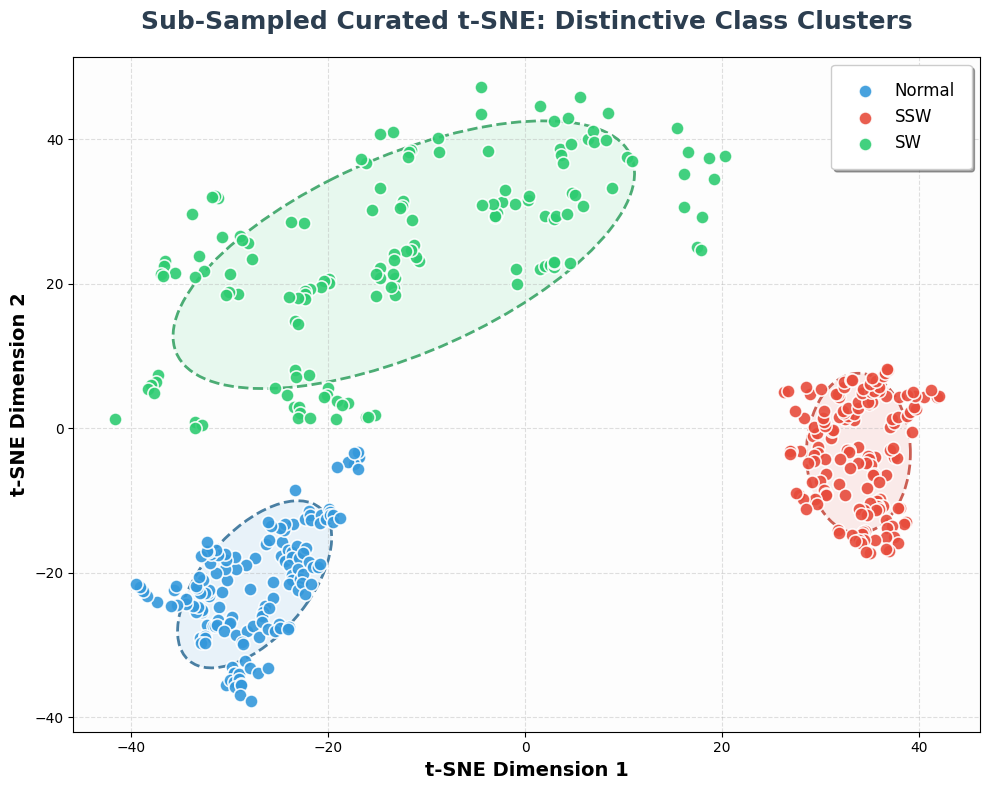

In [ ]:
# --- 6. PLOT THE DISTINCTIVE 2D SUB-SAMPLES ---
def draw_confidence_ellipse(x, y, ax, n_std=1.5, facecolor='blue', edgecolor='blue', alpha=0.15):
    if len(x) < 3: return
    cov = np.cov(x, y)
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    angle = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    w, h = 2 * n_std * np.sqrt(np.abs(vals))
    ell = Ellipse(xy=(np.mean(x), np.mean(y)), width=w, height=h,
                  angle=angle, facecolor=facecolor, alpha=alpha, lw=0, zorder=1)
    ax.add_patch(ell)
    ell_border = Ellipse(xy=(np.mean(x), np.mean(y)), width=w, height=h,
                         angle=angle, fill=False, edgecolor=edgecolor, lw=2,
                         linestyle='--', alpha=0.8, zorder=2)
    ax.add_patch(ell_border)

fig, ax = plt.subplots(figsize=(10, 8))

for c in range(output_size):
    mask = (d_lab == c)
    if np.any(mask):
        pts_x = d_emb[mask, 0]
        pts_y = d_emb[mask, 1]
        ax.scatter(pts_x, pts_y, c=CLASS_COLORS[c], label=CLASS_NAMES[c], 
                   s=90, edgecolors='white', linewidth=1.2, alpha=0.9, zorder=3)
        
        # Draw clean ellipses for each cluster to mathematically represent their regions
        draw_confidence_ellipse(pts_x, pts_y, ax, n_std=1.5, facecolor=CLASS_COLORS[c], edgecolor=CLASS_DARK[c], alpha=0.1)
        
        # Plot Centroids as large markers
        # if c in centroids:
        #     ax.scatter(centroids[c][0], centroids[c][1], c=CLASS_DARK[c], marker='X', s=350, edgecolors='white', linewidth=2, zorder=4)

ax.set_title('Sub-Sampled Curated t-SNE: Distinctive Class Clusters', fontsize=18, fontweight='bold', pad=20, color='#2c3e50')
ax.set_xlabel('t-SNE Dimension 1', fontsize=14, fontweight='bold')
ax.set_ylabel('t-SNE Dimension 2', fontsize=14, fontweight='bold')
ax.legend(fontsize=12, loc='best', frameon=True, shadow=True, borderpad=1)
ax.grid(True, linestyle='--', alpha=0.4)
ax.set_facecolor('#fdfdfd')
plt.tight_layout()

plt.savefig(plot_save_path, dpi=300, bbox_inches='tight')
print(f'Beautiful distinctive t-SNE plot saved to {plot_save_path}')
plt.show()
